<h1 style="text-align: center;">
Diabetes Progression Prediction Using Machine Learning
</h1>

# Part 1 — Data understanding, EDA and split

## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))


from src.regression_metrics import regression_scores
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (r2_score, mean_absolute_error,
                             mean_absolute_percentage_error,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
RANDOM_STATE = 42


## Step 2: Load and View the Dataset

The dataset contains **442 records**, **10 features (X)**, and **1 target (y)**.

- **Features (X):** Age, sex, BMI, blood pressure, and serum measurements.
- **Target (y):** Diabetes disease progression one year after baseline.

We use the features to predict the target.

In [2]:
diabetes = load_diabetes(as_frame=True)  # scaled=True is default
X = diabetes.data.copy()
y = diabetes.target.copy()
df = pd.concat([X, y.rename('progression')], axis=1)
print('X shape:', X.shape)
print('y shape:', y.shape)
display(df.head())
print(diabetes.DESCR[:1600])

X shape: (442, 10)
y shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

## Step 3: Frame the Problem and Metrics

Our goal is to predict diabetes disease progression
using patient features such as BMI, age, and blood pressure.

This is a regression problem because the target is numerical.

We evaluate the models using:

- **R²:** Measures how well the model explains the data.
- **MAE:** Measures the average prediction error.
- **MAPE:** Measures the average percentage error.

In medical screening, false negatives are important because
the model could miss high-risk patients.

## Step 4: Dataset Statistics and Missing Values

We check the dataset's size, statistics, missing values, and duplicates to understand the data and see if cleaning is needed.

In [3]:
print(df.shape)
print(df.dtypes)
display(df.describe().T)
print('Missing values per column:')
print(df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Min target:', y.min())


(442, 11)
age            float64
sex            float64
bmi            float64
bp             float64
s1             float64
s2             float64
s3             float64
s4             float64
s5             float64
s6             float64
progression    float64
dtype: object


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


Missing values per column:
age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
progression    0
dtype: int64
Duplicate rows: 0
Min target: 25.0


### Histogram Analysis

The histograms show that most BMI, BP, and s5 values
are concentrated near zero.

The progression scores are spread over a wider range,
with fewer patients having very high scores.

These graphs help us understand the data distribution.

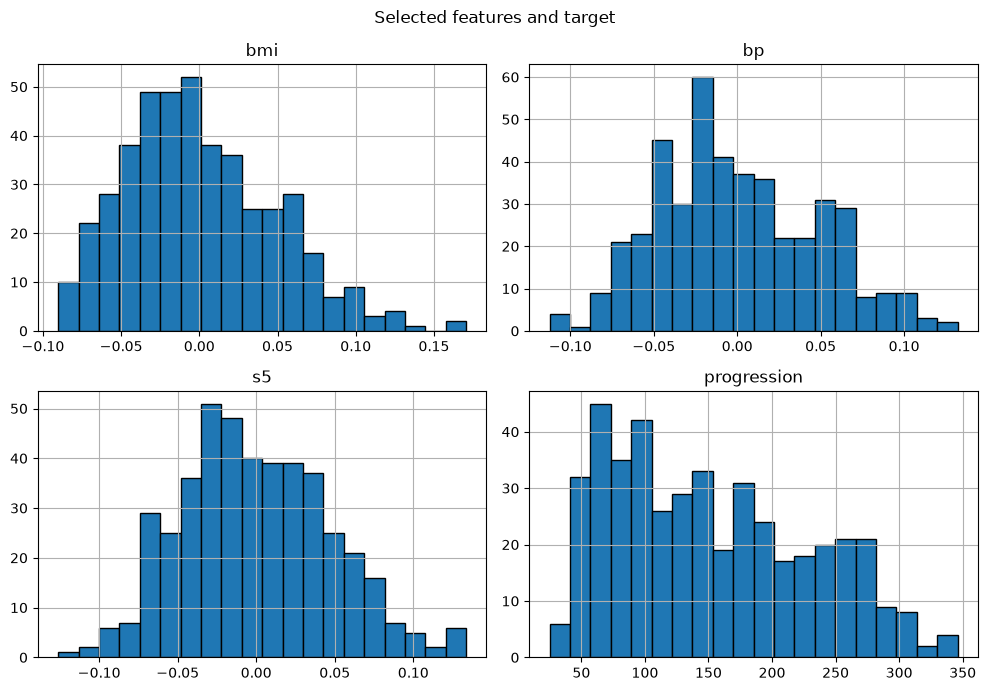

In [4]:
df[["bmi", "bp", "s5", "progression"]].hist(bins=20, figsize=(10,7), edgecolor='black')
plt.suptitle("Selected features and target")
plt.tight_layout()
plt.show()

## Step 6. Required scatter plots
in here, i use scatter plots to understand the relationship between patient features and diabetes progression.

The scatter plots show positive relationships between
BMI, BP, s5, and diabetes progression.

BMI and s5 appear to have stronger relationships with
progression than BP.

However, the points are scattered, suggesting that
one feature alone may not predict progression accurately.

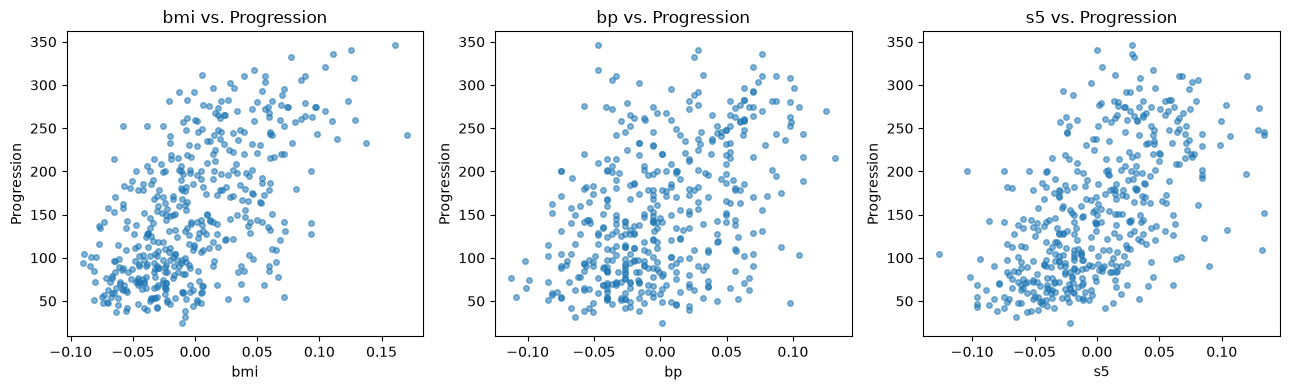

In [5]:
fig, axes=plt.subplots(1, 3, figsize=(13,4))
for ax, feature in zip(axes, ['bmi', 'bp', 's5']):
    ax.scatter(df[feature], df['progression'], alpha=0.55, s=16)
    ax.set(xlabel=feature, ylabel='Progression', title=f'{feature} vs. Progression')
plt.tight_layout()
plt.show()

## Step 7: Correlation Matrix

I use a correlation matrix to understand the relationships between features and diabetes progression.

BMI (0.59) and s5 (0.57) show the strongest positive correlations with progression, while s3 (-0.39) shows a negative correlation.

This helps us identify useful features for prediction.

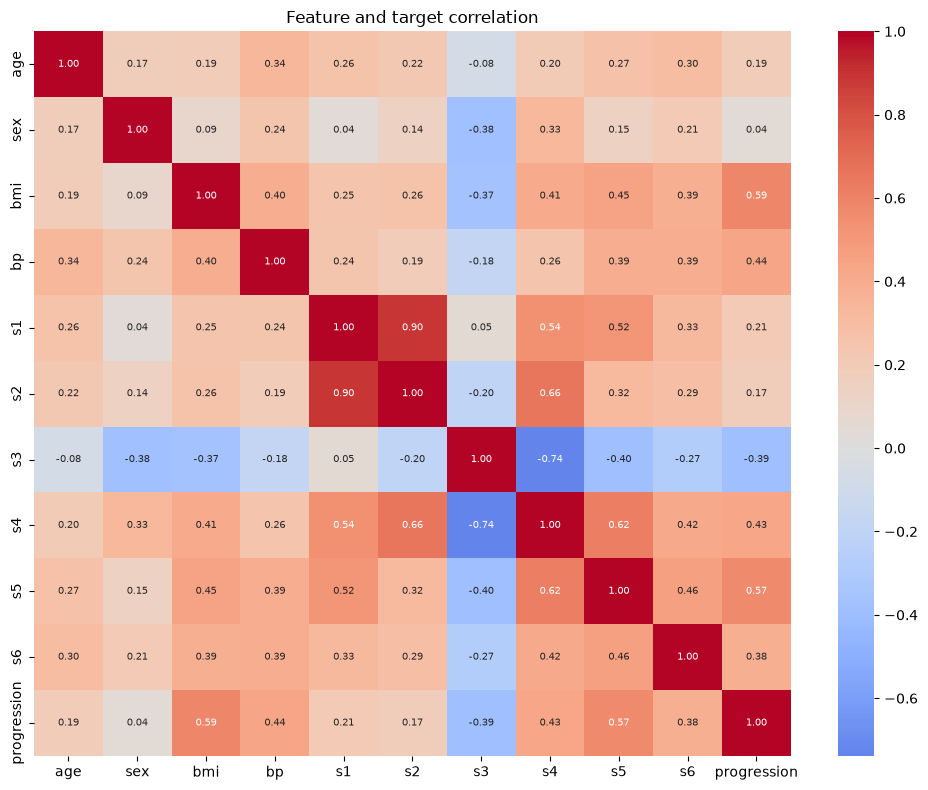

In [6]:
corr=df.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt= '.2f', cmap= 'coolwarm', center=0, annot_kws={'size':7})
plt.title('Feature and target correlation')
plt.tight_layout()
plt.show()

## Step 8: Data Cleaning

The dataset has no missing values or duplicate rows.
All columns contain numerical values, and the features
are already scaled.

Therefore, no additional data cleaning is needed.

# Step 9: Train, Validation, and Test Split

We split the dataset into 75% training, 10% validation,
and 15% testing.

Training data is used to train the model, validation
data helps select the best model, and test data
measures performance on unseen data.

In [7]:
# First reserve 15% as untouched test data.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE)

# Of the remaining 85%, allocate 10/85 to validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=10/85, random_state=RANDOM_STATE)
print('Train:', len(X_train), 'Validation:', len(X_val),
      'Test:', len(X_test))
print('Shares:', len(X_train)/len(X), len(X_val)/len(X),
      len(X_test)/len(X))


Train: 330 Validation: 45 Test: 67
Shares: 0.746606334841629 0.10180995475113122 0.1515837104072398


# Part 2 — Six univariate BMI polynomial models

## Step 10. Create a Reusable Regression Metrics Function

Created `regression_scores()` in a separate Python file, `src/regression_metrics.py`.

The function calculates three evaluation metrics:
- **R²:** Measures how well the model fits the data.
- **MAE:** Measures the average prediction error.
- **MAPE (%):** Measures the average percentage error.

This function will be used later to evaluate and compare regression models.


## Step 11. Fit degrees 0 through 5 using BMI only

**Objective:** Investigate whether BMI alone can predict diabetes progression and determine which polynomial degree provides the best predictive performance.

We use BMI as the only input feature and train polynomial regression models with degrees ranging from 0 to 5, where degree 0 serves as a constant baseline model.

Each model is evaluated on the training and validation sets using R², MAE, and MAPE.

By comparing these metrics, we aim to:

- Assess the predictive ability of BMI alone.
- Determine whether polynomial regression improves performance compared with simple linear regression.
- Identify the polynomial degree with the best validation performance.
- Detect potential overfitting by comparing training and validation results.

The best-performing degree will be selected based on validation performance and subsequently evaluated on the test set.

In [8]:
bmi_train = X_train[['bmi']]
bmi_val = X_val[['bmi']]
bmi_test = X_test[['bmi']]

uni_models = {}
uni_rows = []

for degree in range(6):
    model = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=(degree == 0)
        ),
        LinearRegression()
    )

    model.fit(bmi_train, y_train)
    uni_models[degree] = model

    tr = regression_scores(model, bmi_train, y_train)
    va = regression_scores(model, bmi_val, y_val)

    uni_rows.append({
        'Degree': degree,
        'Train R2': tr['R2'],
        'Val R2': va['R2'],
        'Train MAE': tr['MAE'],
        'Val MAE': va['MAE'],
        'Train MAPE (%)': tr['MAPE (%)'],
        'Val MAPE (%)': va['MAPE (%)']
    })

uni_results = pd.DataFrame(uni_rows)
display(uni_results.round(3))

,Degree,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
0,0,0.000,-0.000,66.548,63.447,63.352,58.793
1,1,0.354,0.449,52.278,41.998,48.462,40.445
2,2,0.355,0.449,52.267,41.758,48.448,40.310
3,3,0.355,0.447,52.223,41.741,48.356,40.259
4,4,0.358,0.449,51.944,41.953,47.964,40.241
5,5,0.359,0.454,51.814,42.083,47.831,40.340


### Univariate Polynomial Regression — Model Selection

The results show that BMI alone has some predictive ability
for diabetes progression.

Degree 5 achieves the highest validation R² (0.454),
indicating that it explains approximately 45.4% of the
variation in diabetes progression.

However, degree 3 achieves the lowest validation MAE (41.741),
while degree 5 has a slightly higher MAE (42.083).

Although degree 5 provides the highest validation R²,
its improvement over degree 1 (R² = 0.449) is very small.

Therefore, a linear model (degree 1) may be preferable
because it offers similar predictive performance with
less complexity.

Overall, higher polynomial degrees do not substantially
improve predictions using BMI alone.

## Step 12. Select the best degree WITHOUT looking at test

The best polynomial degree was selected based on the lowest validation MAE (Mean Absolute Error).

- **Selected degree:** 3
- **Selection method:** Minimum validation MAE
- **Best model:** Polynomial Regression (Degree 3)

This model achieved the lowest average prediction error on the validation dataset among the tested degrees (0–5).


In [9]:
best_degree = int(uni_results.loc[
    uni_results['Val MAE'].idxmin(), 'Degree'])
best_uni = uni_models[best_degree]
print('Selected degree:', best_degree)


Selected degree: 3



### Step 13. Evaluate the Best Univariate Model on Test Data

The selected polynomial regression model (Degree 3) was evaluated on the test dataset using BMI as the only feature.

**Test Results:**
- **R²:** 0.207
- **MAE:** 54.63
- **MAPE:** 48.54%

The model explains approximately 20.7% of the variation in diabetes progression. The prediction errors indicate that BMI alone has limited predictive power.

Using additional features may improve the model's performance.


In [10]:
test_uni_scores = regression_scores(best_uni, bmi_test, y_test)
print('Univariate test results:', test_uni_scores)


Univariate test results: {'R2': 0.2069176933925133, 'MAE': 54.62905711324289, 'MAPE (%)': 48.54079866646053}



## Step 14. Visualize the Best Univariate Model

Plot the training, validation, and test datasets to visualize the relationship between BMI and diabetes progression.

The black line represents predictions from the selected polynomial regression model (Degree 3).

The graph shows a positive relationship between BMI and diabetes progression. However, many observations are far from the prediction line, indicating that BMI alone has limited predictive power.


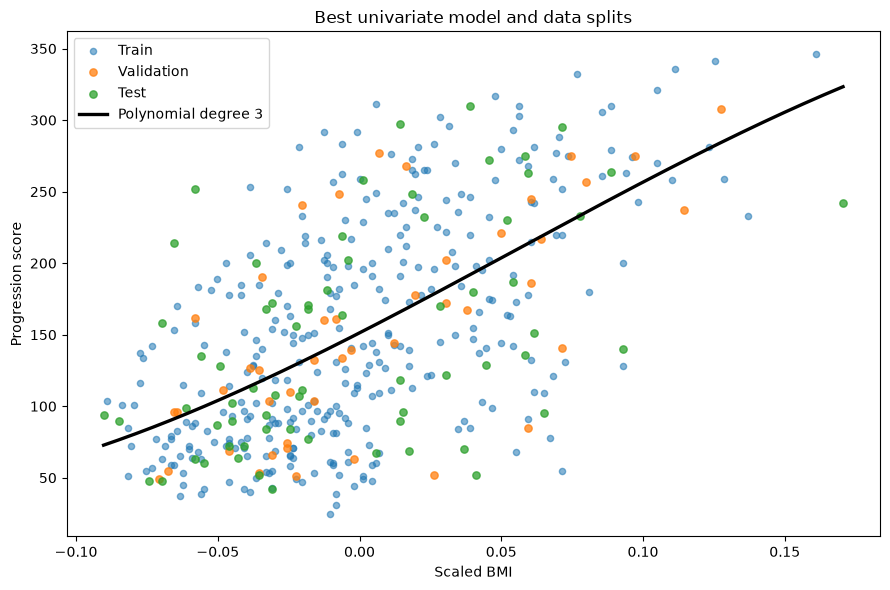

In [11]:
grid = np.linspace(X['bmi'].min(), X['bmi'].max(), 300)
grid_df = pd.DataFrame({'bmi': grid})
plt.figure(figsize=(9, 6))
plt.scatter(bmi_train['bmi'], y_train, s=20, alpha=.55,
            label='Train')
plt.scatter(bmi_val['bmi'], y_val, s=28, alpha=.75,
            label='Validation')
plt.scatter(bmi_test['bmi'], y_test, s=28, alpha=.75,
            label='Test')
plt.plot(grid, best_uni.predict(grid_df), color='black',
         linewidth=2.4, label=f'Polynomial degree {best_degree}')
plt.xlabel('Scaled BMI'); plt.ylabel('Progression score')
plt.title('Best univariate model and data splits')
plt.legend(); plt.tight_layout(); plt.show()


### Polynomial Regression Equation (Degree 3)

We extract the intercept and coefficients from the best model to display the equation used to predict diabetes progression from BMI.

The resulting equation is:

$$
\hat{y} = 151.28 + 1012.43(BMI) + 1028.74(BMI^2) - 6158.21(BMI^3)
$$

This equation shows how the model uses BMI and its polynomial terms to predict diabetes progression.

In [12]:
poly = best_uni.named_steps['polynomialfeatures']
lin = best_uni.named_steps['linearregression']
names = poly.get_feature_names_out(['bmi'])
terms = [f'{lin.intercept_:.2f}']
for name, coef in zip(names, lin.coef_):
    terms.append(f'({coef:+.2f} × {name})')
print('Predicted progression = ' + ' '.join(terms))


Predicted progression = 151.28 (+1012.43 × bmi) (+1028.74 × bmi^2) (-6158.21 × bmi^3)


### Predicting Diabetes Progression for One Person

We select the median scaled BMI value from the training dataset
and use our best polynomial regression model (degree 3) to
predict diabetes progression for a single person.

This demonstrates how the trained model can be used to make
predictions using BMI alone.

In [13]:
chosen_scaled_bmi = float(X_train['bmi'].median())
new_person = pd.DataFrame({'bmi': [chosen_scaled_bmi]})
print('Chosen (scaled) BMI:', chosen_scaled_bmi)
print('Predicted progression:', best_uni.predict(new_person)[0])

Chosen (scaled) BMI: -0.006744860172747491
Predicted progression: 144.4969264284427


### Comparing Model Complexity

We examine the number of features, coefficients, and parameters
in each polynomial regression model.

As the polynomial degree increases, the number of parameters
also increases, making the model more complex.

This helps us understand the relationship between model
complexity, predictive performance, and potential overfitting.

In [14]:
for degree, model in uni_models.items():
    feat = model.named_steps['polynomialfeatures']
    lr = model.named_steps['linearregression']
    names = feat.get_feature_names_out(['bmi'])
    print(f'Degree {degree}: {len(names)} coefficients + '
          f'1 intercept = {len(names) + 1} parameters; '
          f'features: {list(names)}')


Degree 0: 1 coefficients + 1 intercept = 2 parameters; features: ['1']
Degree 1: 1 coefficients + 1 intercept = 2 parameters; features: ['bmi']
Degree 2: 2 coefficients + 1 intercept = 3 parameters; features: ['bmi', 'bmi^2']
Degree 3: 3 coefficients + 1 intercept = 4 parameters; features: ['bmi', 'bmi^2', 'bmi^3']
Degree 4: 4 coefficients + 1 intercept = 5 parameters; features: ['bmi', 'bmi^2', 'bmi^3', 'bmi^4']
Degree 5: 5 coefficients + 1 intercept = 6 parameters; features: ['bmi', 'bmi^2', 'bmi^3', 'bmi^4', 'bmi^5']


## Step 18. Analyze the Errors and Limitations

**Observations:**
- Some predictions have large errors.
- The model overestimates low values and underestimates high values.

**Limitations:**
- The model uses only BMI to predict diabetes progression.
- Other features may improve prediction accuracy.

**Conclusion:**

BMI alone can help predict diabetes progression, but the model is not always accurate.

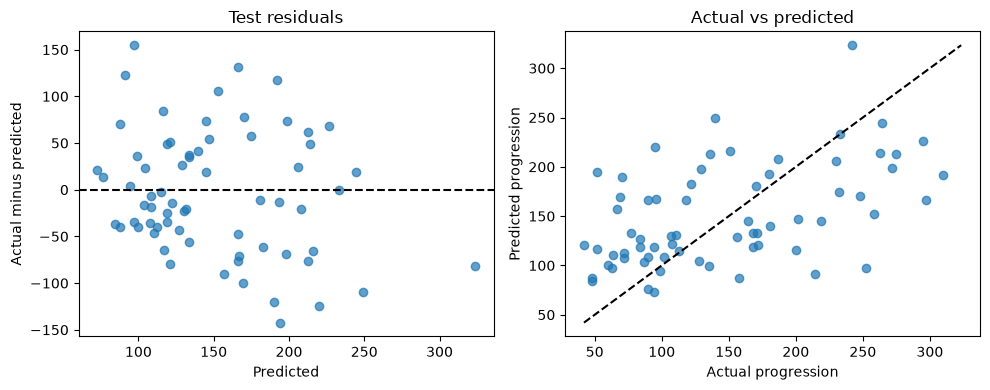

In [15]:
test_pred = best_uni.predict(bmi_test)
residual = y_test - test_pred
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(test_pred, residual, alpha=.7)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Predicted', ylabel='Actual minus predicted',
            title='Test residuals')
axes[1].scatter(y_test, test_pred, alpha=.7)
lo = min(y_test.min(), test_pred.min())
hi = max(y_test.max(), test_pred.max())
axes[1].plot([lo, hi], [lo, hi], 'k--')
axes[1].set(xlabel='Actual progression',
            ylabel='Predicted progression', title='Actual vs predicted')
plt.tight_layout(); plt.show()


# Part 3 — Compare multivariate models

## Step 19. Decide which features to use
We select the independent variables based on their correlation with diabetes progression.

- **Dependent variable (y):** Diabetes progression(target).
- **Independent variables (X):**
  - **BMI (0.595):** Strong positive correlation.
  - **S5 (0.554):** Strong positive correlation (log of triglycerides).
  - **BP (0.445):** Moderate positive correlation.
  - **S3 (-0.380):** Moderate negative correlation (HDL cholesterol).

We select these four features because they show relatively strong relationships with diabetes progression.

The goal is to determine whether using multiple independent variables improves prediction accuracy compared with using BMI alone.

In [17]:
print(pd.concat([X_train, y_train.rename('progression')],axis=1).corr()['progression'].sort_values())
selected_features = ['bmi', 'bp', 's5', 's3']
Xm_train = X_train[selected_features]
Xm_val = X_val[selected_features]
Xm_test = X_test[selected_features]


s3            -0.379803
sex            0.000092
s2             0.172759
s1             0.202655
age            0.211355
s6             0.391529
s4             0.416844
bp             0.444501
s5             0.553574
bmi            0.595181
progression    1.000000
Name: progression, dtype: float64


## ## Step 20. Train and Compare Regression Models

We train seven regression models using four independent variables:
**BMI, BP, S5, and S3**.

The models include:
- Multiple Linear Regression (baseline)
- Polynomial Regression (degrees 2 and 3)
- Decision Tree Regression (depths 3 and 5)
- K-Nearest Neighbors Regression (k=5 and k=15)

We evaluate each model using R², MAE, and MAPE on the training and validation sets.

### Why Do We Use Pipelines?

- **Pipelines:** Combine preprocessing and model training into one process.
- **StandardScaler:** Is fitted only on training data to prevent data leakage from validation and test sets.
- **kNN:** Uses distances between observations, so feature scaling is important.
- **Decision Trees:** Generally do not require feature scaling.
- **Polynomial Regression:** Higher degrees create more polynomial terms, increasing model complexity and the risk of overfitting.

### Objective

The goal is to identify the model with the lowest validation MAE, check for overfitting, and determine whether using multiple independent variables improves prediction accuracy compared with BMI alone.

In [20]:



# Define regression models
regression_models = {
    # Multiple Linear Regression (baseline)
    'Multiple Linear Regression': LinearRegression(),

    # Polynomial Regression
    'Polynomial degree 2': make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    'Polynomial degree 3': make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),

    # Decision Tree Regression
    'Tree depth 3': DecisionTreeRegressor(
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    'Tree depth 5': DecisionTreeRegressor(
        max_depth=5,
        random_state=RANDOM_STATE
    ),

    # K-Nearest Neighbors Regression
    'kNN k=5': make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    ),

    'kNN k=15': make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=15)
    )
}

# Store model evaluation results
reg_rows = []

# Train and evaluate each model
for name, model in regression_models.items():

    # Train model
    model.fit(Xm_train, y_train)

    # Evaluate training and validation performance
    tr = regression_scores(model, Xm_train, y_train)
    va = regression_scores(model, Xm_val, y_val)

    # Store results
    reg_rows.append({
        'Model': name,
        'Train R2': tr['R2'],
        'Val R2': va['R2'],
        'Train MAE': tr['MAE'],
        'Val MAE': va['MAE'],
        'Train MAPE (%)': tr['MAPE (%)'],
        'Val MAPE (%)': va['MAPE (%)']
    })

# Create comparison table
reg_results = pd.DataFrame(reg_rows)

# Sort by lowest validation MAE
display(
    reg_results.sort_values('Val MAE').round(3)
)

# Select the best model based on validation MAE
best_model_name = reg_results.loc[
    reg_results['Val MAE'].idxmin(), 'Model'
]

best_multi = regression_models[best_model_name]

print('Selected model:', best_model_name)


,Model,Train R2,Val R2,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
1,Polynomial degree 2,0.506,0.601,45.151,38.063,39.590,39.308
0,Multiple Linear Regression,0.487,0.588,46.167,38.843,41.086,39.286
2,Polynomial degree 3,0.530,0.589,43.806,39.711,38.333,39.544
6,kNN k=15,0.492,0.592,45.243,39.844,40.228,39.793
5,kNN k=5,0.554,0.546,42.117,40.942,37.219,40.242
3,Tree depth 3,0.524,0.433,43.850,43.891,37.845,42.891
4,Tree depth 5,0.673,0.433,34.705,44.093,30.444,42.239


Selected model: Polynomial degree 2


## Step 21. Choose the Winning Regressor and Test Once

We select the model with the lowest validation MAE and evaluate it on the test set.

- **MAE:** Average prediction error (lower is better).
- **MAPE:** Percentage prediction error (lower is better).
- **R²:** Variation explained by the model (higher is better).

We compare training and validation scores to check for overfitting.

The test set is used only for final evaluation, not to select a new model.

In [21]:
winner_name = reg_results.loc[
    reg_results['Val MAE'].idxmin(), 'Model']
winner_model = regression_models[winner_name]
print('Selected regression model:', winner_name)
print('Test regression scores:',
      regression_scores(winner_model, Xm_test, y_test))


Selected regression model: Polynomial degree 2
Test regression scores: {'R2': 0.43772098142780436, 'MAE': 44.204918923860696, 'MAPE (%)': 38.707605413058}


## Step 22. Compare Model Complexity

We compare the complexity of the seven regression models.

**Observations:**
- Multiple Linear Regression is the simplest model, with 5 parameters.
- Polynomial degree 3 has more parameters (35) than degree 2 (15).
- Tree depth 5 is more complex than tree depth 3.
- kNN uses 5 or 15 neighbors instead of regression coefficients.

**Conclusion:**

More complex models may capture additional patterns but can also overfit. We use validation performance to determine whether the extra complexity improves predictions.

In [23]:

for name, model in regression_models.items():

    if 'Multiple Linear Regression' in name:
        print(
            name,
            ':', len(model.coef_),
            'coefficients + 1 intercept =',
            len(model.coef_) + 1, 'parameters'
        )

    elif 'Polynomial' in name:
        poly = model.named_steps['polynomialfeatures']
        names = poly.get_feature_names_out(selected_features)
        print(
            name, len(names),
            'coefficients + 1 intercept =',
            len(names) + 1, 'parameters'
        )

    elif 'Tree' in name:
        print(
            name,
            'tree nodes:', model.tree_.node_count,
            'leaves:', model.get_n_leaves()
        )

    elif 'kNN' in name:
        knn = model.named_steps['kneighborsregressor']
        print(
            name,
            'k:', knn.n_neighbors,
            '(stores training examples; no regression coefficients)'
        )


Multiple Linear Regression : 4 coefficients + 1 intercept = 5 parameters
Polynomial degree 2 14 coefficients + 1 intercept = 15 parameters
Polynomial degree 3 34 coefficients + 1 intercept = 35 parameters
Tree depth 3 tree nodes: 15 leaves: 8
Tree depth 5 tree nodes: 63 leaves: 32
kNN k=5 k: 5 (stores training examples; no regression coefficients)
kNN k=15 k: 15 (stores training examples; no regression coefficients)


## Step 23. Logistic Regression Classification

We create a separate binary classification task to predict whether diabetes progression is low (0) or high (1).

The threshold is calculated using the median progression value from the training set.

We train two Logistic Regression models with C=0.1 and C=1.0 using BMI, BP, S5, and S3.

We compare their accuracy, precision, recall, and F1 scores to identify the better classification model.



In [24]:
threshold = float(y_train.median())
y_train_bin = (y_train >= threshold).astype(int)
y_val_bin = (y_val >= threshold).astype(int)
y_test_bin = (y_test >= threshold).astype(int)

classification_models = {
    'Logistic C=0.1': make_pipeline(
        StandardScaler(), LogisticRegression(C=0.1,
                                              max_iter=2000,
                                              random_state=RANDOM_STATE)),
    'Logistic C=1.0': make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0,
                                              max_iter=2000,
                                              random_state=RANDOM_STATE))
}

def classification_scores(model, features, labels):
    pred = model.predict(features)
    return {'Accuracy': accuracy_score(labels, pred),
            'Precision': precision_score(labels, pred,
                                         zero_division=0),
            'Recall': recall_score(labels, pred, zero_division=0),
            'F1': f1_score(labels, pred, zero_division=0)}

class_rows = []
for name, model in classification_models.items():
    model.fit(Xm_train, y_train_bin)
    tr = classification_scores(model, Xm_train, y_train_bin)
    va = classification_scores(model, Xm_val, y_val_bin)
    class_rows.append({'Model': name,
                       **{'Train '+k: v for k,v in tr.items()},
                       **{'Val '+k: v for k,v in va.items()}})
class_results = pd.DataFrame(class_rows)
display(class_results.round(3))


,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Val Accuracy,Val Precision,Val Recall,Val F1
0,Logistic C=0.1,0.727,0.732,0.723,0.727,0.822,0.792,0.864,0.826
1,Logistic C=1.0,0.724,0.730,0.717,0.723,0.822,0.792,0.864,0.826


## Step 24. Select the Best Classifier

We select Logistic Regression (C=0.1) because it has the highest validation recall.

**Test Results:**
- Accuracy: 76.12%
- Precision: 71.88%
- Recall: 76.67%
- F1 Score: 74.19%

The model correctly predicts 51 out of 67 cases but misses 7 HIGH progression cases.

**Conclusion:** The model performs reasonably well but still makes some classification errors.

In [25]:
best_clf_name = class_results.loc[
    class_results['Val Recall'].idxmax(), 'Model']
best_clf = classification_models[best_clf_name]
print('Selected classifier:', best_clf_name)
print('Test classification metrics:',
      classification_scores(best_clf, Xm_test, y_test_bin))
print('Test confusion matrix (rows=true, columns=predicted):')
print(confusion_matrix(y_test_bin, best_clf.predict(Xm_test)))


Selected classifier: Logistic C=0.1
Test classification metrics: {'Accuracy': 0.7611940298507462, 'Precision': 0.71875, 'Recall': 0.7666666666666667, 'F1': 0.7419354838709677}
Test confusion matrix (rows=true, columns=predicted):
[[28  9]
 [ 7 23]]


Step 25. Final conclusions: fill-in template